# Portfolio 5.1.P: Anomaly detection methods

**Question.** What methods for anomaly detection are there? When should you use them? Explain some that are easy to implement in practical examples.

**Plan.**
1. A toy example that shows why a global distance threshold fails and LOF fixes it.
2. Seven methods on the Taiwan credit data, all scored the same way.
3. How the methods react to contaminated training data, to their settings, and to injected anomalies.
4. Conclusions: which method when.

**Convention.** Every detector returns a score where **higher means more anomalous**. This makes them comparable.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.covariance import MinCovDet, EmpiricalCovariance
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score, average_precision_score

import prep   # Oscar/prep.py: loads the shared split and applies fixes 1-4

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 0
plt.rcParams["figure.dpi"] = 110

## 1. Toy example: why one distance threshold fails

Two normal groups: a **dense** cluster and a **sparse** cluster. One true anomaly sits just outside the dense cluster.

* **kNN distance** is the distance to the k-th nearest neighbour. It uses one global scale.
* **LOF** compares a point's local density with its neighbours' densities.

The anomaly is close to the dense cluster, but not as isolated as the ordinary points in the sparse cluster.

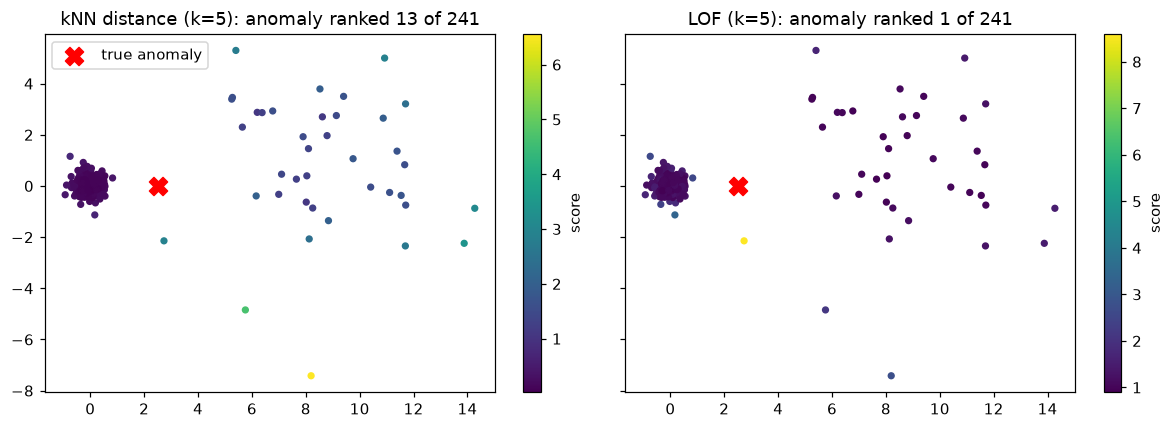

In [2]:
rng = np.random.default_rng(SEED)
dense = rng.normal([0, 0], 0.3, size=(200, 2))
sparse = rng.normal([9, 0], 2.5, size=(40, 2))
anomaly = np.array([[2.5, 0.0]])
X_toy = np.vstack([dense, sparse, anomaly])
k = 5

dist, _ = NearestNeighbors(n_neighbors=k + 1).fit(X_toy).kneighbors(X_toy)
knn_score = dist[:, -1]                                   # distance to the k-th neighbour
lof_score = -LocalOutlierFactor(n_neighbors=k).fit(X_toy).negative_outlier_factor_

def rank_of_last(score):
    return int((score > score[-1]).sum() + 1)              # 1 = most anomalous

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, score, name in zip(axes, [knn_score, lof_score], ["kNN distance (k=5)", "LOF (k=5)"]):
    sc = ax.scatter(X_toy[:-1, 0], X_toy[:-1, 1], c=score[:-1], cmap="viridis", s=14)
    ax.scatter(*X_toy[-1], marker="X", s=140, c="red", label="true anomaly")
    ax.set_title(f"{name}: anomaly ranked {rank_of_last(score)} of {len(score)}")
    plt.colorbar(sc, ax=ax, label="score")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Reading the plot.** Under kNN the sparse cluster scores higher than the anomaly, because its points are far from their neighbours. Any threshold that flags the anomaly also flags many normal sparse points. LOF judges each point against its own neighbours, so the sparse cluster looks normal and the anomaly stands out.

## 2. Data and protocol

Data: the Taiwan credit card default data from the shared split (`taiwan-train.csv`, `taiwan-validation.csv`). The test set is not touched.

**Which points are the anomalies?** The label `default payment next month` is used only for evaluation. Defaulters are treated as the "anomalous" class. This is a stand-in, because a defaulter is not necessarily far from other customers. The results therefore show how much of the default signal is geometric.

**Protocol (semi-supervised).** Fit each detector on **non-defaulting customers only** from the training set. Score the validation set. Judge with:

* **AUROC**: the chance a random defaulter scores higher than a random non-defaulter. 0.5 is chance.
* **Average precision (AP)**: precision averaged over recall. Its chance level is the default rate. Use it because the classes are imbalanced.

Fixes 1-4 from `prep.py` are applied. The scaler is learned from the fitting data only. To keep runs fast, at most `MAX_TRAIN` rows are used for fitting.

In [3]:
MAX_TRAIN = 8000

def make_data(clean=True, seed=SEED):
    """Fit data and validation data, prepared with prep.transform.
    clean=True  : fit on non-defaulters only (semi-supervised).
    clean=False : fit on everyone, so the fit data is contaminated."""
    X_tr, y_tr = prep.load("train")
    X_va, y_va = prep.load("validation")
    X_fit = X_tr[y_tr == 0] if clean else X_tr
    X_fit = X_fit.sample(min(MAX_TRAIN, len(X_fit)), random_state=seed)
    X_fit, X_va = prep.transform(X_fit, X_va)
    return X_fit, X_va, y_va

X_fit, X_val, y_val = make_data(clean=True)
CONT = [c for c in X_fit.columns if c in prep.AMOUNTS or c == "AGE"]   # continuous columns only
print("fit rows:", X_fit.shape, "| validation rows:", X_val.shape)
print("continuous features:", len(CONT), "of", X_fit.shape[1])
print(f"validation default rate (the AP chance level): {y_val.mean():.3f}")

fit rows: (8000, 50) | validation rows: (5999, 50)
continuous features: 14 of 50
validation default rate (the AP chance level): 0.221


## 3. The detectors

One function builds every detector from the fitting data. Each detector is a function from a data frame to scores (higher = more anomalous).

| Method | Family | Score |
|---|---|---|
| Mahalanobis, classic | multivariate | squared distance with sample mean and covariance |
| Mahalanobis, MCD | multivariate, robust | same, with mean and covariance from the MCD subset |
| Gaussian mixture | density | negative log-likelihood |
| kNN distance | distance | distance to the k-th neighbour |
| LOF | distance, local | ratio of local densities |
| PCA, SPE | reconstruction | squared distance **off** the subspace |
| PCA, Hotelling T2 | reconstruction | distance **within** the subspace |
| Isolation Forest | isolation | short average path length |
| One-class SVM | boundary | distance outside the learned boundary |

Mahalanobis uses the continuous columns only. The one-hot dummies would make the covariance nearly singular. The other methods use all columns.

In [4]:
def fit_detectors(X_fit, k=20, nu=0.05, gamma_mult=1.0, n_pca=0.90, seed=SEED):
    d = {}

    # Multivariate: Mahalanobis distance (continuous columns)
    emp = EmpiricalCovariance().fit(X_fit[CONT])
    d["Mahalanobis (classic)"] = lambda X: emp.mahalanobis(X[CONT])
    mcd = MinCovDet(random_state=seed).fit(X_fit[CONT])
    d["Mahalanobis (MCD)"] = lambda X: mcd.mahalanobis(X[CONT])

    # Density: Gaussian mixture, score = -log p(x)
    gmm = GaussianMixture(n_components=5, covariance_type="full", reg_covar=1e-2,
                          random_state=seed).fit(X_fit)
    d["Gaussian mixture"] = lambda X: -gmm.score_samples(X)

    # Distance: kNN distance, and LOF
    nn = NearestNeighbors(n_neighbors=k).fit(X_fit)
    d["kNN distance"] = lambda X: nn.kneighbors(X)[0][:, -1]
    lof = LocalOutlierFactor(n_neighbors=k, novelty=True).fit(X_fit)
    d["LOF"] = lambda X: -lof.score_samples(X)

    # Reconstruction: PCA with SPE (off-subspace) and Hotelling T2 (within-subspace)
    pca = PCA(n_components=n_pca, random_state=seed).fit(X_fit)
    def spe(X):
        Z = pca.transform(X)
        return ((np.asarray(X) - pca.inverse_transform(Z)) ** 2).sum(axis=1)
    def t2(X):
        Z = pca.transform(X)
        return (Z ** 2 / pca.explained_variance_).sum(axis=1)
    d["PCA SPE"] = spe
    d["PCA Hotelling T2"] = t2

    # Isolation: Isolation Forest
    iso = IsolationForest(n_estimators=200, random_state=seed).fit(X_fit)
    d["Isolation Forest"] = lambda X: -iso.score_samples(X)

    # Boundary: one-class SVM with an RBF kernel
    gamma = gamma_mult / (X_fit.shape[1] * X_fit.to_numpy().var())   # sklearn's 'scale' x gamma_mult
    svm = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X_fit)
    d["One-class SVM"] = lambda X: -svm.decision_function(X)
    return d

def evaluate(detectors, X, y):
    rows = []
    for name, f in detectors.items():
        s = f(X)
        rows.append({"method": name, "AUROC": roc_auc_score(y, s), "AP": average_precision_score(y, s)})
    return pd.DataFrame(rows).set_index("method")

%time detectors = fit_detectors(X_fit)

CPU times: user 2.45 s, sys: 953 ms, total: 3.41 s
Wall time: 1.02 s


## 4. Results on the Taiwan data (clean fit data)

AP chance level = 0.221


,AUROC,AP
method,,
PCA Hotelling T2,0.725,0.441
Isolation Forest,0.702,0.409
One-class SVM,0.697,0.418
kNN distance,0.692,0.397
Gaussian mixture,0.634,0.296
Mahalanobis (classic),0.628,0.292
PCA SPE,0.618,0.305
Mahalanobis (MCD),0.572,0.243
LOF,0.452,0.194


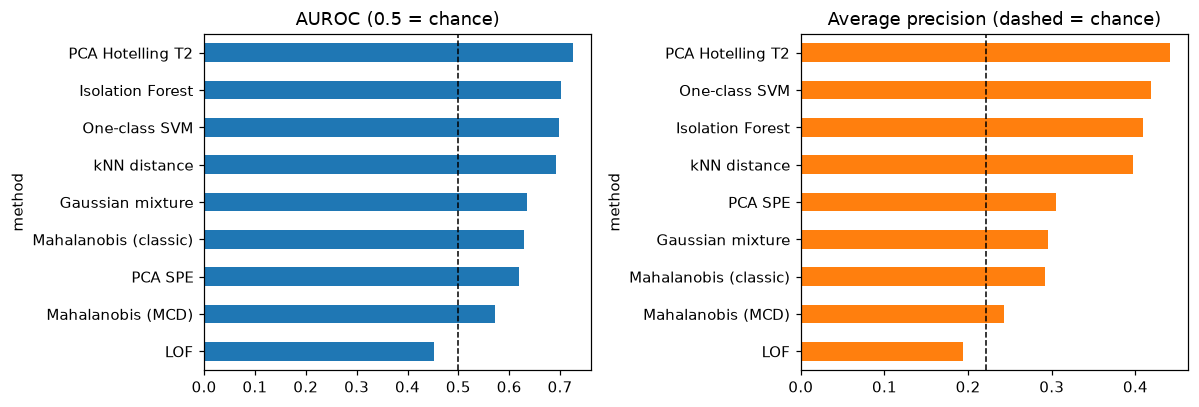

In [5]:
res = evaluate(detectors, X_val, y_val).sort_values("AUROC", ascending=False)
print(f"AP chance level = {y_val.mean():.3f}")
display(res.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
res["AUROC"].sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].axvline(0.5, color="k", ls="--", lw=1); axes[0].set_title("AUROC (0.5 = chance)")
res["AP"].sort_values().plot.barh(ax=axes[1], color="tab:orange")
axes[1].axvline(y_val.mean(), color="k", ls="--", lw=1); axes[1].set_title("Average precision (dashed = chance)")
plt.tight_layout(); plt.show()

## 5. How much do the methods disagree?

Rank correlation between the score vectors. A low value means two methods flag different customers. This is the argument for combining methods, or for choosing by what kind of anomaly you expect.

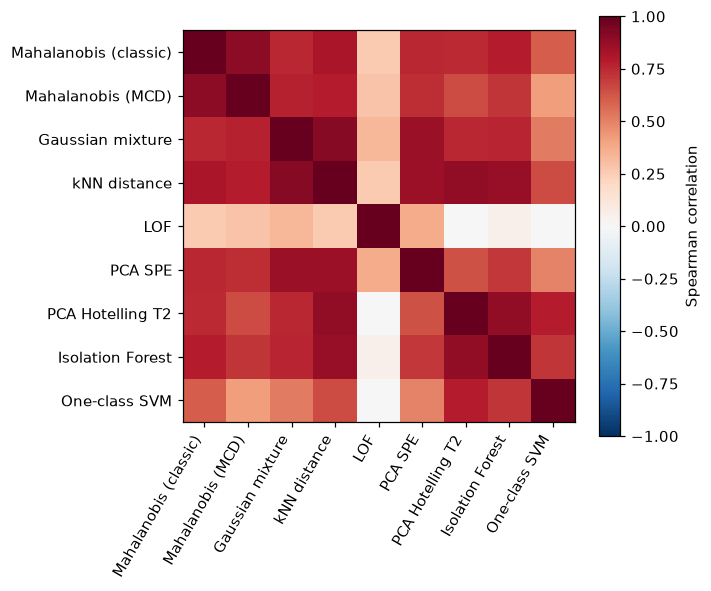

In [6]:
scores = pd.DataFrame({n: f(X_val) for n, f in detectors.items()}, index=X_val.index)
corr = scores.corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
plt.colorbar(im, label="Spearman correlation"); plt.tight_layout(); plt.show()

## 6. Contaminated fit data

Semi-supervised methods assume the fit data is clean. Here the fit data is a random sample of **all** training customers, so about a fifth are defaulters. A method that is robust to contamination should lose little.

In [7]:
X_fit_c, X_val_c, y_val_c = make_data(clean=False)
res_c = evaluate(fit_detectors(X_fit_c), X_val_c, y_val_c)
cmp = pd.DataFrame({"AUROC clean": res["AUROC"], "AUROC contaminated": res_c["AUROC"]})
cmp["change"] = cmp["AUROC contaminated"] - cmp["AUROC clean"]
display(cmp.sort_values("change").round(3))

,AUROC clean,AUROC contaminated,change
method,,,
kNN distance,0.692,0.654,-0.038
PCA Hotelling T2,0.725,0.690,-0.035
One-class SVM,0.697,0.672,-0.025
Isolation Forest,0.702,0.682,-0.020
PCA SPE,0.618,0.598,-0.020
Mahalanobis (classic),0.628,0.610,-0.018
LOF,0.452,0.443,-0.009
Gaussian mixture,0.634,0.626,-0.008
Mahalanobis (MCD),0.572,0.574,0.002


## 7. Sensitivity to settings

Slide 5 and slide 10 say kNN and LOF depend on k, and the one-class SVM depends on the kernel bandwidth. Here is how much.

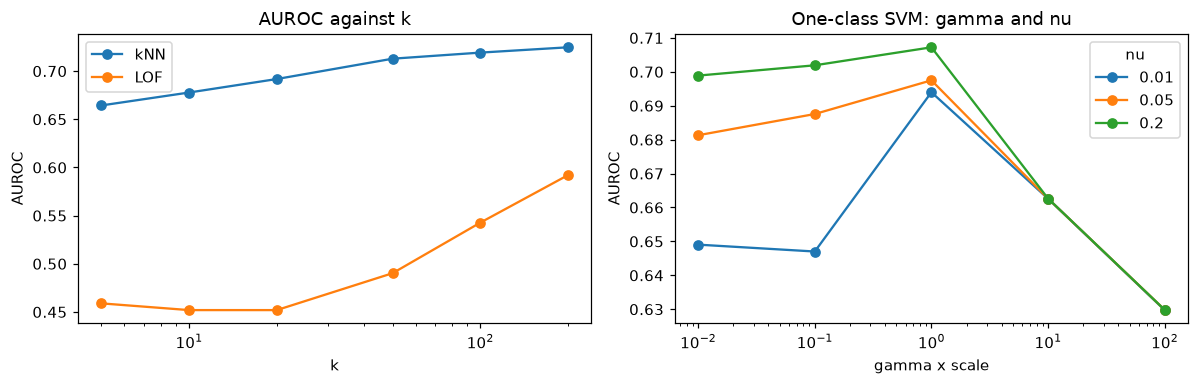

,kNN,LOF
k,,
5,0.664,0.459
10,0.678,0.452
20,0.692,0.452
50,0.713,0.490
100,0.719,0.543
200,0.725,0.592


nu,0.01,0.05,0.20
gamma x scale,,,
0.01,0.649,0.681,0.699
0.10,0.647,0.688,0.702
1.00,0.694,0.697,0.707
10.00,0.663,0.663,0.663
100.00,0.630,0.630,0.630


Isolation Forest AUROC over 5 seeds: mean 0.702, sd 0.0042


In [8]:
ks = [5, 10, 20, 50, 100, 200]
rows = []
for k_ in ks:
    nn_ = NearestNeighbors(n_neighbors=k_).fit(X_fit)
    lof_ = LocalOutlierFactor(n_neighbors=k_, novelty=True).fit(X_fit)
    rows.append({"k": k_,
                 "kNN": roc_auc_score(y_val, nn_.kneighbors(X_val)[0][:, -1]),
                 "LOF": roc_auc_score(y_val, -lof_.score_samples(X_val))})
sens_k = pd.DataFrame(rows).set_index("k")

rows = []
for g in [0.01, 0.1, 1, 10, 100]:
    for nu_ in [0.01, 0.05, 0.2]:
        gamma_ = g / (X_fit.shape[1] * X_fit.to_numpy().var())
        s_ = -OneClassSVM(kernel="rbf", nu=nu_, gamma=gamma_).fit(X_fit).decision_function(X_val)
        rows.append({"gamma x scale": g, "nu": nu_, "AUROC": roc_auc_score(y_val, s_)})
sens_svm = pd.DataFrame(rows).pivot(index="gamma x scale", columns="nu", values="AUROC")

seeds = pd.Series({s: roc_auc_score(y_val, -IsolationForest(n_estimators=200, random_state=s)
                                    .fit(X_fit).score_samples(X_val)) for s in range(5)})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sens_k.plot(ax=axes[0], marker="o", logx=True); axes[0].set_ylabel("AUROC"); axes[0].set_title("AUROC against k")
sens_svm.plot(ax=axes[1], marker="o", logx=True); axes[1].set_ylabel("AUROC"); axes[1].set_title("One-class SVM: gamma and nu")
plt.tight_layout(); plt.show()
display(sens_k.round(3))
display(sens_svm.round(3))
print(f"Isolation Forest AUROC over 5 seeds: mean {seeds.mean():.3f}, sd {seeds.std():.4f}")

## 8. Injected anomalies: a test with known ground truth

Defaulters are a weak stand-in for anomalies. Here the truth is known by construction. Take normal validation customers and add **100 synthetic anomalies**: copy a normal customer and shift **3 randomly chosen continuous features by 5 standard deviations**. These are subspace anomalies. Each looks ordinary in most columns, which is the high-dimensional difficulty from slide 11.

In [9]:
rng = np.random.default_rng(SEED)
X_norm = X_val[y_val == 0].sample(2000, random_state=SEED)
X_anom = X_norm.sample(100, random_state=1).copy()
shifted = []                                            # which columns were shifted, per injected point
for i in range(len(X_anom)):
    cols = [str(c) for c in rng.choice(CONT, size=3, replace=False)]
    shifted.append(cols)
    X_anom.iloc[i, [X_anom.columns.get_loc(c) for c in cols]] += 5.0
X_inj = pd.concat([X_norm, X_anom])
emp_cov = EmpiricalCovariance().fit(X_fit[CONT])        # reused in section 9
emp_loc, emp_prec = emp_cov.location_, emp_cov.precision_
y_inj = np.r_[np.zeros(len(X_norm)), np.ones(len(X_anom))]

res_inj = evaluate(detectors, X_inj, y_inj)
cmp2 = pd.DataFrame({"AUROC defaulters": res["AUROC"], "AUROC injected": res_inj["AUROC"],
                     "AP injected": res_inj["AP"]}).sort_values("AUROC injected", ascending=False)
print(f"AP chance level (injected) = {y_inj.mean():.3f}")
display(cmp2.round(3))

AP chance level (injected) = 0.048


,AUROC defaulters,AUROC injected,AP injected
method,,,
Mahalanobis (classic),0.628,0.999,0.979
Gaussian mixture,0.634,0.995,0.789
PCA SPE,0.618,0.987,0.619
One-class SVM,0.697,0.986,0.602
Mahalanobis (MCD),0.572,0.978,0.832
LOF,0.452,0.975,0.774
kNN distance,0.692,0.975,0.450
PCA Hotelling T2,0.725,0.905,0.235
Isolation Forest,0.702,0.632,0.072


## 9. Interpretability: why was a point flagged?

An investigator needs to know why. Mahalanobis distance splits exactly by feature: the squared distance is the sum over features j of (x - mu)_j * [Sigma^-1 (x - mu)]_j. Take the first injected customer. We know which three features were shifted, so we can check whether the explanation finds them.

In [10]:
Xa = X_inj.iloc[2000:]                                  # the injected points
x = Xa[CONT].iloc[0].to_numpy() - emp_loc
contrib = pd.Series(x * (emp_prec @ x), index=CONT).sort_values(ascending=False)
print("Features actually shifted by +5 sd:", shifted[0])
print(f"Total squared Mahalanobis distance: {contrib.sum():.1f}")
display(contrib.head(6).round(1))

Features actually shifted by +5 sd: ['PAY_AMT1', 'BILL_AMT6', 'PAY_AMT3']
Total squared Mahalanobis distance: 313.5


PAY_AMT1     75.8
PAY_AMT3     74.9
BILL_AMT6    68.3
BILL_AMT1    31.1
PAY_AMT5     26.4
LIMIT_BAL    11.6
dtype: float64

## 10. Conclusions

**On the credit data (defaulters as anomalies).**
* Every method is weak. The best AUROC is 0.725 (PCA Hotelling T2), and the best AP is 0.441 against a chance level of 0.221. The leaders are PCA T2, Isolation Forest, one-class SVM and kNN, all close to 0.70.
* LOF scores 0.45 at k=20, which is below chance. It only reaches 0.59 at k=200. A likely reason is that defaulters sit in typical, dense regions of feature space (for example a common late-payment pattern), so they are not locally sparse. This is a hypothesis, not something tested here.
* A defaulter is a customer with a particular outcome, not a customer who is geometrically unusual. When labels exist, a supervised model is the right tool. Anomaly detection fits when labels are missing or the anomalies are too rare or too varied to learn.

**With known anomalies (injected).**
* Most methods find the shifted points easily (AUROC 0.97 to 0.999). Classic Mahalanobis is best. This is partly by design, because it sees exactly the continuous columns that were shifted.
* **Isolation Forest drops to 0.63.** It chooses features at random among all 50 columns, and only 3 of them carry the shift. It is a strong default in general but weak for this subspace case. This is the high-dimension caveat from slide 11 seen from the other side.
* PCA Hotelling T2 is third from last because bills and payments are correlated, so a shift in them lies mostly inside the PCA subspace. SPE looks off the subspace and does better.

**Contamination.** Training on all customers lowered AUROC for every method except robust Mahalanobis (MCD), which was unchanged. The largest loss was kNN, at 0.038. This matches the slide, but the sizes are modest here.

**Settings matter.**
* kNN and LOF improved as k grew from 5 to 200.
* The one-class SVM is stable near the default gamma and gets worse when gamma is 10 times larger or more.
* Isolation Forest varies little between seeds (sd about 0.004).

**Which method when.**

| Situation | First choice | Why |
|---|---|---|
| Quick default on many features, anomalies are broadly unusual | Isolation Forest | fast, few settings |
| Few correlated numeric features, roughly Gaussian | Mahalanobis (MCD if contaminated) | principled threshold, easy to explain |
| Clusters with different density | LOF | local, not global, threshold |
| Sensor-like data near a low-dimensional structure | PCA with SPE and T2 | two complementary scores |
| Multimodal normal behaviour, need a likelihood | Gaussian mixture | probabilistic score |
| Clean normal data, curved boundary | One-class SVM | flexible, but tune gamma and nu |

**Limits of this study.**
* One train and validation split.
* The k and SVM sweeps were read off the validation set. The test set was not used.
* Defaulters as anomalies is a stand-in, and the injected anomalies are simple.
* Fitting used at most 8,000 rows. The test set is left for final reporting.